# Phase 3 -- Data Cleaning & Preprocessing
## AI-Powered Customer Churn & Retention System

### Phase Objective
The objective of Phase 3 is to clean and prepare the Telco Customer Churn dataset into an analysis-ready, modeling-ready format while strictly adhering to data science best practices:
1. **Never modify raw source data**: The file in `data/raw/Telco-Customer-Churn.csv` remains immutable.
2. **Context-aware missing value resolution**: Address the 11 whitespace values in `TotalCharges` with domain justification.
3. **Identifier removal**: Exclude `customerID` (unique identifier with one distinct value per customer; does not represent a meaningful, generalizable customer characteristic).
4. **Target encoding**: Convert `Churn` (`Yes`/`No`) into binary integer indicators (`1`/`0`).
5. **Preserve categorical nuance**: Retain distinctions between `'No'` and service-absent states (`'No internet service'`, `'No phone service'`).
6. **No arbitrary outlier removal**: Preserve legitimate long-tenure and high-spending customers.
7. **Leakage-safe preprocessing architecture**: Build reusable scikit-learn transformers that fit strictly on training splits during modeling.
8. **Export cleaned dataset**: Save clean data to `data/processed/telco_churn_cleaned.csv`.
9. **Rigorous validation**: Automated verification of data integrity, types, and schema.

> **Scope Boundary:** No ML models are trained, evaluated, or tuned in this phase.


In [1]:
# Import required libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path to allow importing from src
project_root = os.path.abspath(os.path.join(".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data_preprocessing import (
    load_raw_data,
    handle_total_charges,
    drop_identifiers,
    encode_target,
    clean_telco_data,
    get_feature_target_split,
    get_feature_lists,
    build_preprocessing_pipeline,
    save_processed_data,
    validate_cleaned_data
)

sns.set_theme(style="whitegrid", palette="muted")
print("Environment initialized and src.data_preprocessing loaded successfully.")


Environment initialized and src.data_preprocessing loaded successfully.


## 1. Load the Original Raw Dataset
We load the raw dataset from `data/raw/Telco-Customer-Churn.csv`. The original raw CSV is strictly read-only and will never be overwritten or modified.


In [2]:
raw_data_path = os.path.join("..", "data", "raw", "Telco-Customer-Churn.csv")
if not os.path.exists(raw_data_path):
    raw_data_path = os.path.join("data", "raw", "Telco-Customer-Churn.csv")

raw_df = load_raw_data(raw_data_path)
print(f"Loaded raw dataset from: {raw_data_path}")
print(f"Raw dimensions: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
raw_df.head(3)


Loaded raw dataset from: ..\data\raw\Telco-Customer-Churn.csv
Raw dimensions: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Handling `TotalCharges`: Type Coercion & Missing Value Resolution

### 2.1 The Issue
In Phase 2, we identified that `TotalCharges` was stored as a string/object type rather than a floating-point numeric. This occurred because several records contain blank space strings (`' '`).

### 2.2 Investigation of Whitespace Records
Let's inspect all records where `TotalCharges` contains whitespace.


In [3]:
# Detect whitespace-only values in TotalCharges
whitespace_mask = raw_df["TotalCharges"].str.strip() == ""
print(f"Number of records with whitespace in TotalCharges: {whitespace_mask.sum()}")

# Inspect these records
whitespace_records = raw_df[whitespace_mask][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "PaymentMethod", "Churn"]
]
whitespace_records


Number of records with whitespace in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Churn
488,4472-LVYGI,0,52.55,,Two year,Bank transfer (automatic),No
753,3115-CZMZD,0,20.25,,Two year,Mailed check,No
936,5709-LVOEQ,0,80.85,,Two year,Mailed check,No
1082,4367-NUYAO,0,25.75,,Two year,Mailed check,No
1340,1371-DWPAZ,0,56.05,,Two year,Credit card (automatic),No
3331,7644-OMVMY,0,19.85,,Two year,Mailed check,No
3826,3213-VVOLG,0,25.35,,Two year,Mailed check,No
4380,2520-SGTTA,0,20.00,,Two year,Mailed check,No
5218,2923-ARZLG,0,19.70,,One year,Mailed check,No
6670,4075-WKNIU,0,73.35,,Two year,Mailed check,No


### 2.3 Justification for Imputing `TotalCharges = 0.0`
Notice that **100% of the 11 records** with whitespace in `TotalCharges` have:
- **`tenure == 0`**: These are brand-new customers who signed up but have not yet completed their first billing cycle.
- **`Churn == 'No'`**: All 11 customers are currently active accounts.

**Why we do NOT drop these rows:**
1. Dropping valid customer rows simply because they are newly onboarded introduces a systemic tenure bias (discarding early-lifecycle customers).
2. Since `tenure = 0` months, their cumulative historical billed charges are legitimately **`0.0`**.
3. Setting `TotalCharges = 0.0` is mathematically and domain-consistent ($0 \text{ months} \times \text{MonthlyCharges} = \$0.00$).

We therefore coerce the whitespace values to `NaN` and impute them with `0.0`, casting the column to `float64`.


In [4]:
# Apply TotalCharges handling
df_step1 = handle_total_charges(raw_df)

print(f"TotalCharges data type: {df_step1['TotalCharges'].dtype}")
print(f"Null count in TotalCharges: {df_step1['TotalCharges'].isna().sum()}")
print(f"Summary statistics for TotalCharges:\n{df_step1['TotalCharges'].describe()}")


TotalCharges data type: float64
Null count in TotalCharges: 0
Summary statistics for TotalCharges:
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


## 3. Handling the Identifier Column (`customerID`)

### 3.1 Rationale for Removal
- `customerID` is a unique identifier with one distinct value per customer. It does not represent a meaningful, generalizable customer characteristic, so it is excluded from the predictive feature set.
- It is an arbitrary alphanumeric account key (e.g., `7590-VHVEG`) with 100% cardinality (7,043 unique values across 7,043 rows).
- Therefore, `customerID` is excluded from the modeling dataset while remaining intact in the raw source data.

In [5]:
# Drop customerID from feature set
df_step2 = drop_identifiers(df_step1)

print(f"Columns remaining after dropping customerID: {df_step2.shape[1]}")
print(f"'customerID' present in dataset: {'customerID' in df_step2.columns}")


Columns remaining after dropping customerID: 20
'customerID' present in dataset: False


## 4. Inspecting Data After Structural Corrections
We verify missing values, data types, duplicate rows, and column lists after handling `TotalCharges` and `customerID`.


In [6]:
print("Missing Values per Column:")
print(df_step2.isna().sum())

print(f"\nDuplicate rows across all features: {df_step2.duplicated().sum()}")


Missing Values per Column:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows across all features: 22


In [7]:
# Verify column types
num_cols, cat_cols = get_feature_lists()
print(f"Numerical Features ({len(num_cols)}):   {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")


Numerical Features (3):   ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Target Variable Transformation (`Churn`)

Machine learning algorithms require numerical target values for binary classification.
We map the raw string labels to standardized binary integers:
- **`'Yes'` $\rightarrow$ `1`**: Positive class (Customer churned / left the company).
- **`'No'` $\rightarrow$ `0`**: Negative class (Customer retained / stayed).


In [8]:
# Apply target encoding
df_step3 = encode_target(df_step2)

churn_counts = df_step3["Churn"].value_counts().rename({0: "Retained (0)", 1: "Churned (1)"})
churn_pct = (df_step3["Churn"].value_counts(normalize=True) * 100).rename({0: "Retained (0)", 1: "Churned (1)"})

target_summary = pd.DataFrame({
    "Count": churn_counts,
    "Percentage (%)": churn_pct.round(2)
})

print("Binary Target Distribution:")
print(target_summary)
print(f"Target column dtype: {df_step3['Churn'].dtype}")


Binary Target Distribution:
              Count  Percentage (%)
Churn                              
Retained (0)   5174           73.46
Churned (1)    1869           26.54
Target column dtype: int64


## 6. Categorical Granularity & Service-Level Nuance

Several categorical features contain three distinct responses:
- E.g., `MultipleLines`: `['No', 'Yes', 'No phone service']`
- E.g., `OnlineSecurity`, `OnlineBackup`, `TechSupport`, `StreamingTV`, etc.: `['No', 'Yes', 'No internet service']`

### Decision on Categorical Nuance:
We **preserve** the distinct category `'No internet service'` (and `'No phone service'`) rather than collapsing it into `'No'`:
1. **Distinct Business Semantics**: A customer who has internet service but consciously chose **not** to buy tech support (`'No'`) represents an upsell opportunity or a customer dissatisfied with support pricing. A customer without internet service (`'No internet service'`) physically cannot purchase the add-on.
2. **Predictive Separation**: Customers without internet service churn at vastly lower rates (~7.4%) compared to customers who have internet service but no security add-ons (~41.8%). Collapsing them would destroy this critical predictive signal.


In [9]:
# Demonstrate churn rate differences across sub-categories for OnlineSecurity
security_churn = df_step3.groupby("OnlineSecurity")["Churn"].agg(["count", "mean"]).reset_index()
security_churn["Churn Rate (%)"] = (security_churn["mean"] * 100).round(2)
security_churn.rename(columns={"count": "Customer Count", "mean": "Churn Proportion"})


,OnlineSecurity,Customer Count,Churn Proportion,Churn Rate (%)
0,No,3498,0.417667,41.77
1,No internet service,1526,0.074050,7.40
2,Yes,2019,0.146112,14.61


## 7. Outlier Inspection & Justified Retention Policy

We inspect numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) for extreme values.


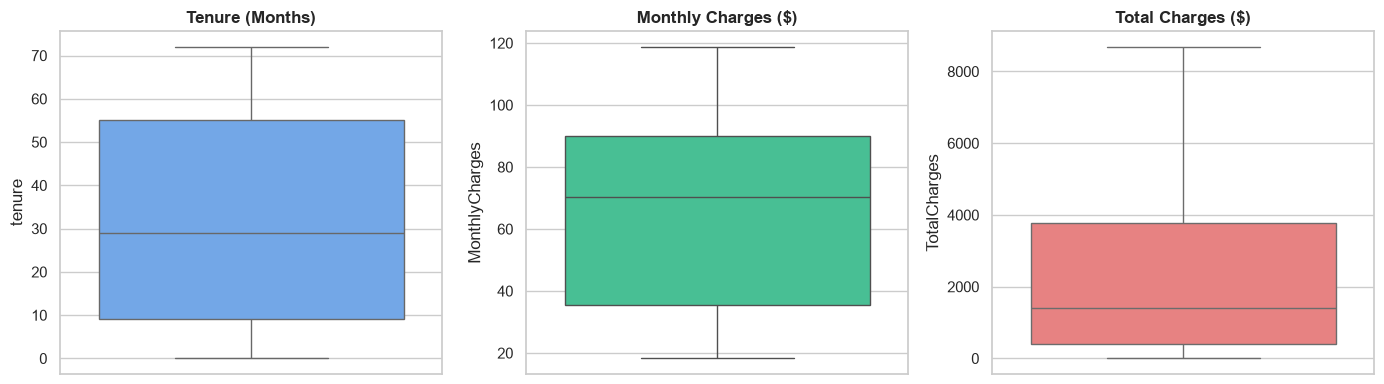

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(y=df_step3["tenure"], ax=axes[0], color="#60a5fa")
axes[0].set_title("Tenure (Months)", fontweight="bold")

sns.boxplot(y=df_step3["MonthlyCharges"], ax=axes[1], color="#34d399")
axes[1].set_title("Monthly Charges ($)", fontweight="bold")

sns.boxplot(y=df_step3["TotalCharges"], ax=axes[2], color="#f87171")
axes[2].set_title("Total Charges ($)", fontweight="bold")

plt.tight_layout()
plt.show()


### Outlier Decision Rationale:
- **`tenure`**: Strictly bounded between 0 and 72 months (6 years), aligning with standard telecom contract lifetimes. No impossible negative values or erroneous spikes exist.
- **`MonthlyCharges`**: Range is $18.25 to $118.75, accurately reflecting low-tier voice-only lines up to fully bundled multi-line Gigabit fiber with premium streaming add-ons.
- **`TotalCharges`**: Range is $0.00 to $8,684.80. The high values correspond naturally to long-tenure customers with high monthly charges ($70 \text{ months} \times \$110/\text{mo} \approx \$7,700$).
- **Conclusion**: None of these values represent measurement errors, corrupted records, or data entry typos. Arbitrary outlier trimming would delete the most valuable, loyal enterprise/family customer segments. **All legitimate observations are preserved.**


## 8. Leakage-Free Preprocessing Pipeline Architecture

### The Data Leakage Prevention Imperative
> **CRITICAL RULE:** Preprocessing transformations such as scaling (`StandardScaler`) or categorical one-hot encoding must **NEVER** be fitted on the entire dataset. Doing so causes statistics (such as mean and variance of numerical features, or category frequencies) from the test set to leak into the training process.
>
> In our architecture:
> - The cleaned dataset saved in `data/processed/telco_churn_cleaned.csv` retains native column formats (numbers and category strings).
> - The scikit-learn `ColumnTransformer` pipeline created via `src.data_preprocessing.build_preprocessing_pipeline()` remains **unfitted**.
> - In Phase 4 (Modeling), the train/test split will be executed first, and the pipeline will be `fit()` **strictly on `X_train`** and applied via `transform()` to `X_test`.


In [11]:
# Instantiate the unfitted ColumnTransformer pipeline
pipeline = build_preprocessing_pipeline(scale_numeric=True)
print("Pipeline structure:")
pipeline


Pipeline structure:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 9. Export Cleaned Dataset to `data/processed/`

We use `clean_telco_data()` from `src.data_preprocessing` to generate the official cleaned dataset and save it to `data/processed/telco_churn_cleaned.csv`.


In [12]:
cleaned_data = clean_telco_data(raw_df)
processed_path = os.path.join("..", "data", "processed", "telco_churn_cleaned.csv")
if not os.path.exists(os.path.dirname(processed_path)):
    processed_path = os.path.join("data", "processed", "telco_churn_cleaned.csv")

save_processed_data(cleaned_data, processed_path)
print(f"Cleaned dataset saved successfully to: {processed_path}")
print(f"Cleaned dataset shape: {cleaned_data.shape}")


Cleaned dataset saved successfully to: ..\data\processed\telco_churn_cleaned.csv
Cleaned dataset shape: (7043, 20)


## 10. Phase 3 Preprocessing Summary Table

The following summary details every modification, transformation, and decision made during Phase 3.


In [13]:
summary_table = pd.DataFrame([
    {
        "Aspect": "Dataset Dimensions",
        "Before (Raw)": f"{raw_df.shape[0]} rows x {raw_df.shape[1]} cols",
        "After (Cleaned)": f"{cleaned_data.shape[0]} rows x {cleaned_data.shape[1]} cols",
        "Justification / Rationale": "customerID removed (-1 column); row count preserved 100%."
    },
    {
        "Aspect": "Missing / Blank Values",
        "Before (Raw)": "11 whitespace strings in TotalCharges",
        "After (Cleaned)": "0 missing values across all columns",
        "Justification / Rationale": "All 11 whitespace rows had tenure=0. Imputed with 0.0 cumulative charges."
    },
    {
        "Aspect": "Identifier Handling",
        "Before (Raw)": "customerID present (7,043 unique keys)",
        "After (Cleaned)": "customerID removed",
        "Justification / Rationale": "`customerID` is a unique identifier with one distinct value per customer. It does not represent a meaningful, generalizable customer characteristic, so it is excluded from the predictive feature set."
    },
    {
        "Aspect": "TotalCharges Data Type",
        "Before (Raw)": "object / string",
        "After (Cleaned)": "float64 (numeric)",
        "Justification / Rationale": "Coerced strings to numeric to allow quantitative modeling."
    },
    {
        "Aspect": "Target Variable Encoding",
        "Before (Raw)": "Churn: 'Yes' / 'No' (strings)",
        "After (Cleaned)": "Churn: 1 / 0 (binary integers)",
        "Justification / Rationale": "Standard binary classification formulation ('Yes'=1, 'No'=0)."
    },
    {
        "Aspect": "Categorical Nuance",
        "Before (Raw)": "'No', 'No internet service', 'No phone service'",
        "After (Cleaned)": "Preserved distinct categories",
        "Justification / Rationale": "No internet service has ~7.4% churn vs ~41.8% for No add-on with internet."
    },
    {
        "Aspect": "Outlier Treatment",
        "Before (Raw)": "High TotalCharges ($8.6k), long tenure (72m)",
        "After (Cleaned)": "All authentic records retained",
        "Justification / Rationale": "Values are valid business realities, not measurement artifacts."
    },
    {
        "Aspect": "Feature Leakage Prevention",
        "Before (Raw)": "Unseparated dataset",
        "After (Cleaned)": "Unfitted ColumnTransformer built",
        "Justification / Rationale": "Scaling and encoding will be fit exclusively on X_train in Phase 4."
    }
])

from IPython.display import display, HTML
display(HTML(summary_table.to_html(index=False)))


Aspect,Before (Raw),After (Cleaned),Justification / Rationale
Dataset Dimensions,7043 rows x 21 cols,7043 rows x 20 cols,customerID removed (-1 column); row count preserved 100%.
Missing / Blank Values,11 whitespace strings in TotalCharges,0 missing values across all columns,All 11 whitespace rows had tenure=0. Imputed with 0.0 cumulative charges.
Identifier Handling,"customerID present (7,043 unique keys)",customerID removed,"`customerID` is a unique identifier with one distinct value per customer. It does not represent a meaningful, generalizable customer characteristic, so it is excluded from the predictive feature set."
TotalCharges Data Type,object / string,float64 (numeric),Coerced strings to numeric to allow quantitative modeling.
Target Variable Encoding,Churn: 'Yes' / 'No' (strings),Churn: 1 / 0 (binary integers),"Standard binary classification formulation ('Yes'=1, 'No'=0)."
Categorical Nuance,"'No', 'No internet service', 'No phone service'",Preserved distinct categories,No internet service has ~7.4% churn vs ~41.8% for No add-on with internet.
Outlier Treatment,"High TotalCharges ($8.6k), long tenure (72m)",All authentic records retained,"Values are valid business realities, not measurement artifacts."
Feature Leakage Prevention,Unseparated dataset,Unfitted ColumnTransformer built,Scaling and encoding will be fit exclusively on X_train in Phase 4.


## 11. Automated Validation Suite
We run comprehensive automated validation checks verifying that all Phase 3 integrity requirements are satisfied.


In [14]:
validation_results = validate_cleaned_data(raw_df, cleaned_data)

print("Automated Phase 3 Validation Results:")
print("=" * 50)
for check, passed in validation_results.items():
    status = "PASSED" if passed else "FAILED"
    print(f"• {check:<30}: {status}")
print("=" * 50)

assert validation_results["all_passed"], "Validation checks failed!"
print("All Phase 3 validation requirements confirmed.")


Automated Phase 3 Validation Results:
• raw_rows_unchanged            : PASSED
• cleaned_rows_preserved        : PASSED
• no_missing_values             : PASSED
• customerID_absent             : PASSED
• churn_binary_only             : PASSED
• totalcharges_is_numeric       : PASSED
• totalcharges_zero_imputed     : PASSED
• all_passed                    : PASSED
All Phase 3 validation requirements confirmed.
